In [1]:
import pandas as pd
import numpy as np
import math

In [4]:
train_path = "optdigits.tra"
test_path = "optdigits.tes"

In [5]:
train_data = pd.read_csv(train_path, header=None)
test_data = pd.read_csv(test_path, header=None)

print(train_data.shape)
print(test_data.shape)

display(train_data.head())

(3823, 65)
(1797, 65)


,0,1,2,3,4,5,6,7,8,9,...,55,56,57,58,59,60,61,62,63,64
0,0,1,6,15,12,1,0,0,0,7,...,0,0,0,6,14,7,1,0,0,0
1,0,0,10,16,6,0,0,0,0,7,...,0,0,0,10,16,15,3,0,0,0
2,0,0,8,15,16,13,0,0,0,1,...,0,0,0,9,14,0,0,0,0,7
3,0,0,0,3,11,16,0,0,0,0,...,0,0,0,0,1,15,2,0,0,4
4,0,0,5,14,4,0,0,0,0,0,...,0,0,0,4,12,14,7,0,0,6


In [7]:
X_train = train_data.iloc[:, :-1]
y_train = train_data.iloc[:, -1]

X_test = test_data.iloc[:, :-1]
y_test = test_data.iloc[:, -1]

print(X_train.shape)
print(y_train.shape)

(3823, 64)
(3823,)


# Funcion 1

In [14]:
def euclidean_distance(point1, point2):
    if len(point1) != len(point2):
        raise ValueError("Los puntos deben tener las mismas dimensiones")

    point1 = np.array(point1)
    point2 = np.array(point2)

    distance = np.sqrt(np.sum((point1 - point2) ** 2))

    return distance

# Funcion 2

In [15]:
def create_kmeans(data, n_clusters=8, max_iter=1000,
                  tol=0.0001, randomstate=None):

    data = np.asarray(data, dtype=float)

    #matriz valida?
    if data.ndim != 2 or data.shape[0] == 0 or data.shape[1] == 0:
        raise ValueError("data debe ser una matriz no vacía")

    
    if not isinstance(n_clusters, (int, np.integer)) or isinstance(n_clusters, (bool, np.bool_)):
        raise ValueError("n_clusters debe ser un entero")

    if n_clusters < 1 or n_clusters > len(data):
        raise ValueError("n_clusters debe estar entre 1 y el número de puntos")

  
    rng = np.random.default_rng(randomstate)

    # indices aleatorios de los puntos iniciales
    indices = rng.choice(len(data), size=n_clusters, replace=False)

    # inicializar los centroides con puntos de los datos
    centroids = data[indices].copy()

    # Guardar la información del modelo
    kmeans = {
        "data": data,
        "n_clusters": n_clusters,
        "centroids": centroids,
        "max_iter": max_iter,
        "tol": tol,
        "labels": None,
        "inertia": None
    }

    return kmeans

# Funcion 3

In [43]:
def kmeans_fit(kmeans, verbose=True):
    data = kmeans["data"]
    centroids = kmeans["centroids"].copy()
    max_iter = kmeans["max_iter"]
    tol = kmeans["tol"]

    for iteration in range(max_iter):
        distances = np.sqrt(
            np.sum((data[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2, axis=2)
        )

        labels = np.argmin(distances, axis=1)

        new_centroids = centroids.copy()

        for cluster in range(kmeans["n_clusters"]):
            cluster_points = data[labels == cluster]

            if len(cluster_points) > 0:
                new_centroids[cluster] = np.mean(cluster_points, axis=0)

        movements = np.sqrt(np.sum((new_centroids - centroids) ** 2, axis=1))
        max_movement = np.max(movements)

        centroids = new_centroids

        if verbose:
            print(f"Iteración {iteration + 1}: movimiento máximo = {max_movement:.6f}")

        if max_movement <= tol:
            if verbose:
                print("El algoritmo ha convergido.")
            break

    distances = np.sqrt(
        np.sum((data[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2, axis=2)
    )
    labels = np.argmin(distances, axis=1)

    kmeans["centroids"] = centroids
    kmeans["labels"] = labels
    kmeans["n_iter"] = iteration + 1

    return kmeans


# Funcion 4

In [19]:

def inertia(kmeans):

    data = kmeans["data"]
    centroids = kmeans["centroids"]
    labels = kmeans["labels"]

    if labels is None:
        raise ValueError("Primero debes entrenar el modelo con kmeans_fit")

    total_inertia = 0

    # Recorrer todos los puntos
    for i in range(len(data)):

        # Obtener el centroide asignado al punto
        centroid = centroids[labels[i]]

        # Calcular la distancia euclidiana
        distance = euclidean_distance(data[i], centroid)

        # Sumar la distancia al cuadrado
        total_inertia += distance ** 2

    # Guardar la inercia en el modelo
    kmeans["inertia"] = total_inertia

    return total_inertia


# Funcion 5

In [37]:
import matplotlib.pyplot as plt

def elbow(data, min=2, max=8, max_iter=100, tol=0.001,
          randomstate=None):

    k_values = []
    inertias = []

    for k in range(min, max + 1):
        print(f"Calculando k={k}...")

        modelo = create_kmeans(
            data,
            n_clusters=k,
            max_iter=max_iter,
            tol=tol,
            randomstate=randomstate
        )

        modelo = kmeans_fit(modelo, verbose=False)
        resultado = inertia(modelo)

        k_values.append(k)

        inertias.append(resultado)

        print(f"Inercia: {resultado:.2f}")

    plt.figure(figsize=(8, 5))
    plt.plot(k_values, inertias, marker="o")
    plt.xlabel("Número de clusters (k)")
    plt.ylabel("Inercia")
    plt.title("Método del codo para K-Means")
    plt.xticks(k_values)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return None


Calculando k=2...
Inercia: 4082182.60
Calculando k=3...
Inercia: 3764174.07
Calculando k=4...
Inercia: 3514822.44
Calculando k=5...
Inercia: 3182326.24
Calculando k=6...
Inercia: 2959945.31
Calculando k=7...
Inercia: 2835678.06
Calculando k=8...
Inercia: 2689037.48


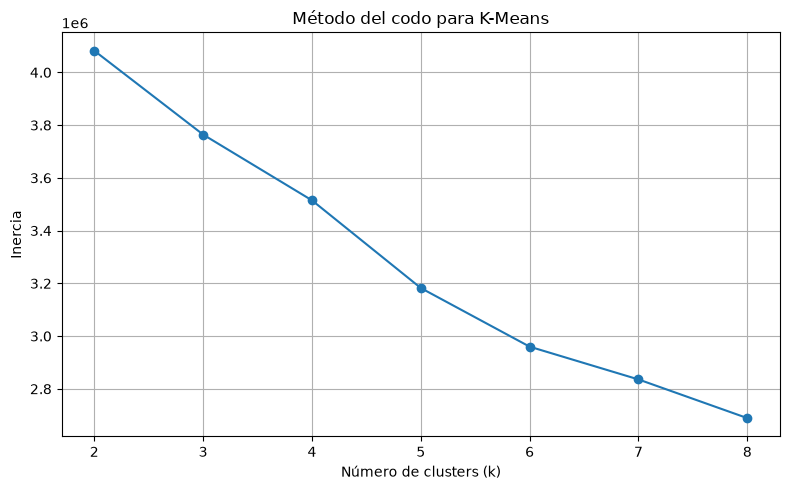

In [44]:
elbow(
    X_train,
    min=2,
    max=8,
    max_iter=100,
    tol=0.001,
    randomstate=42
)